<a href="https://colab.research.google.com/github/VETTOORLIJO/DS_VettoorLijo/blob/master/Multi_LR_TitanicNew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
df= sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [39]:
df.dtypes

,0
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,category
who,object


In [40]:
df.duplicated().sum()

np.int64(107)

In [41]:
df=df.drop_duplicates()

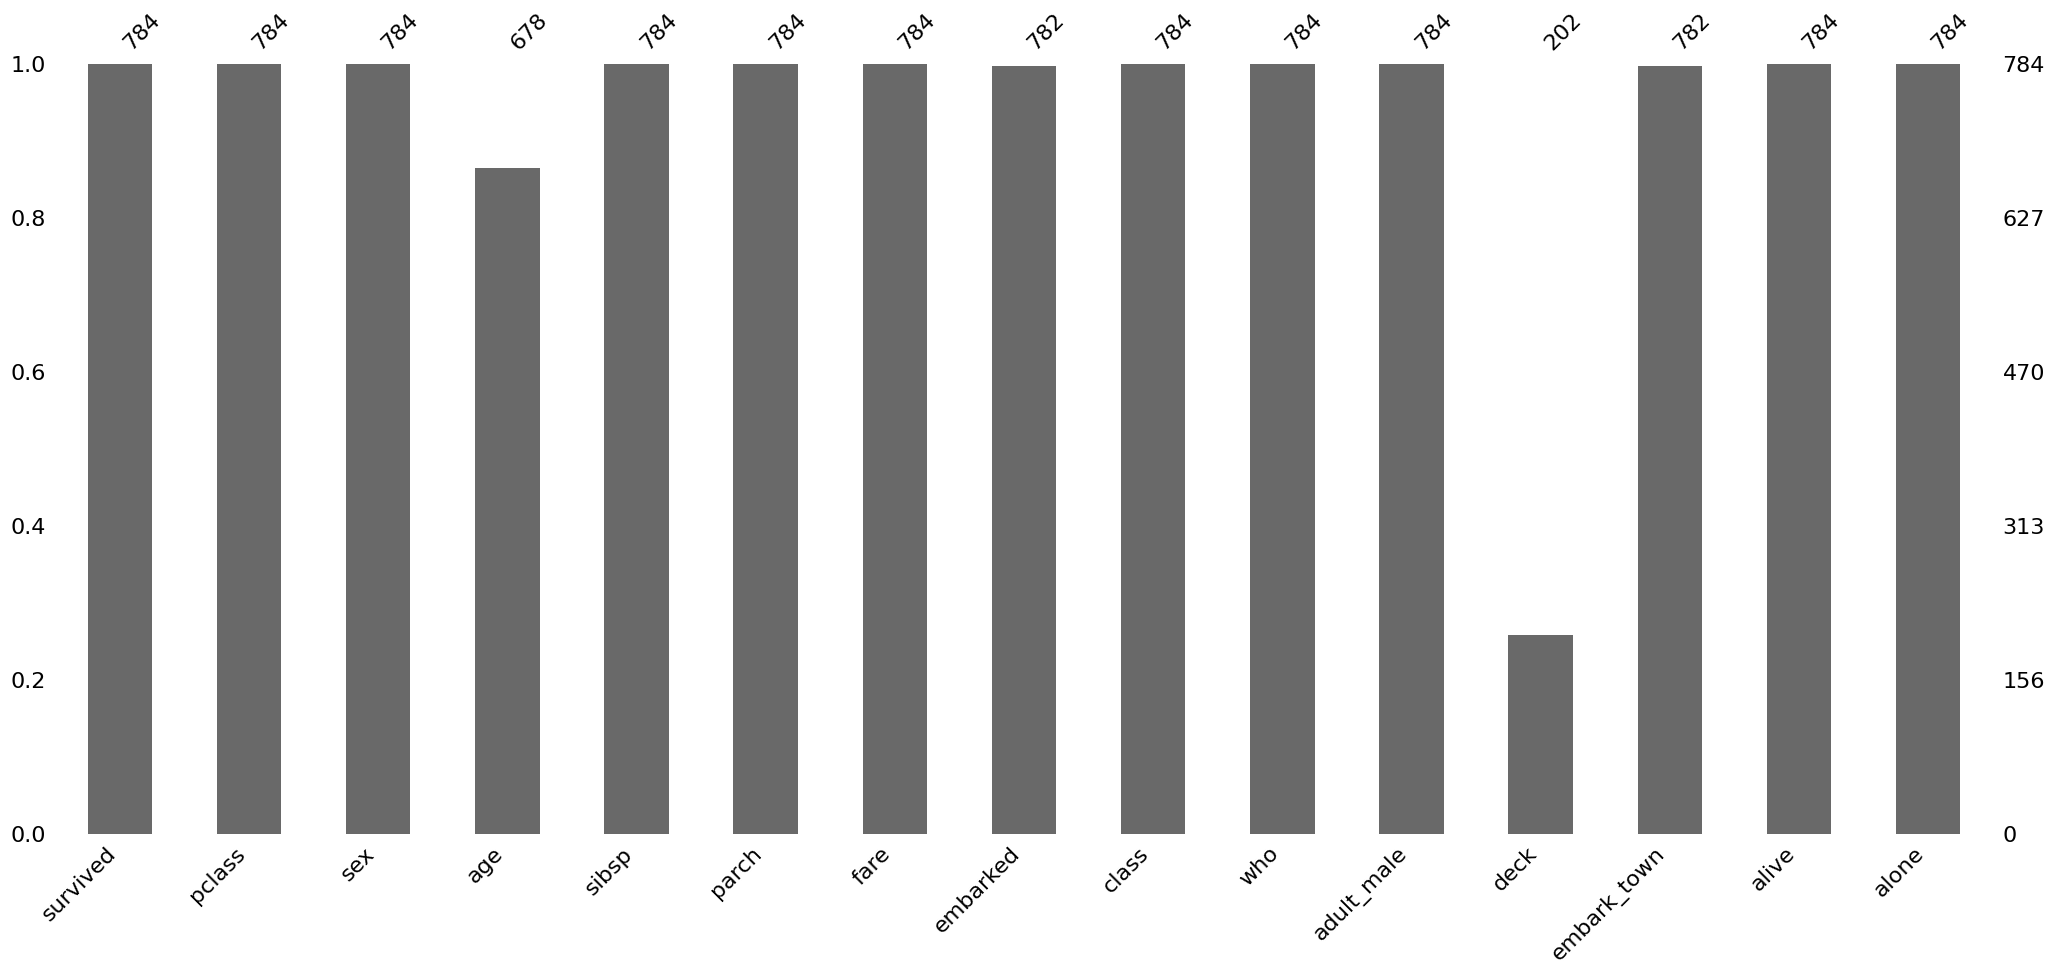

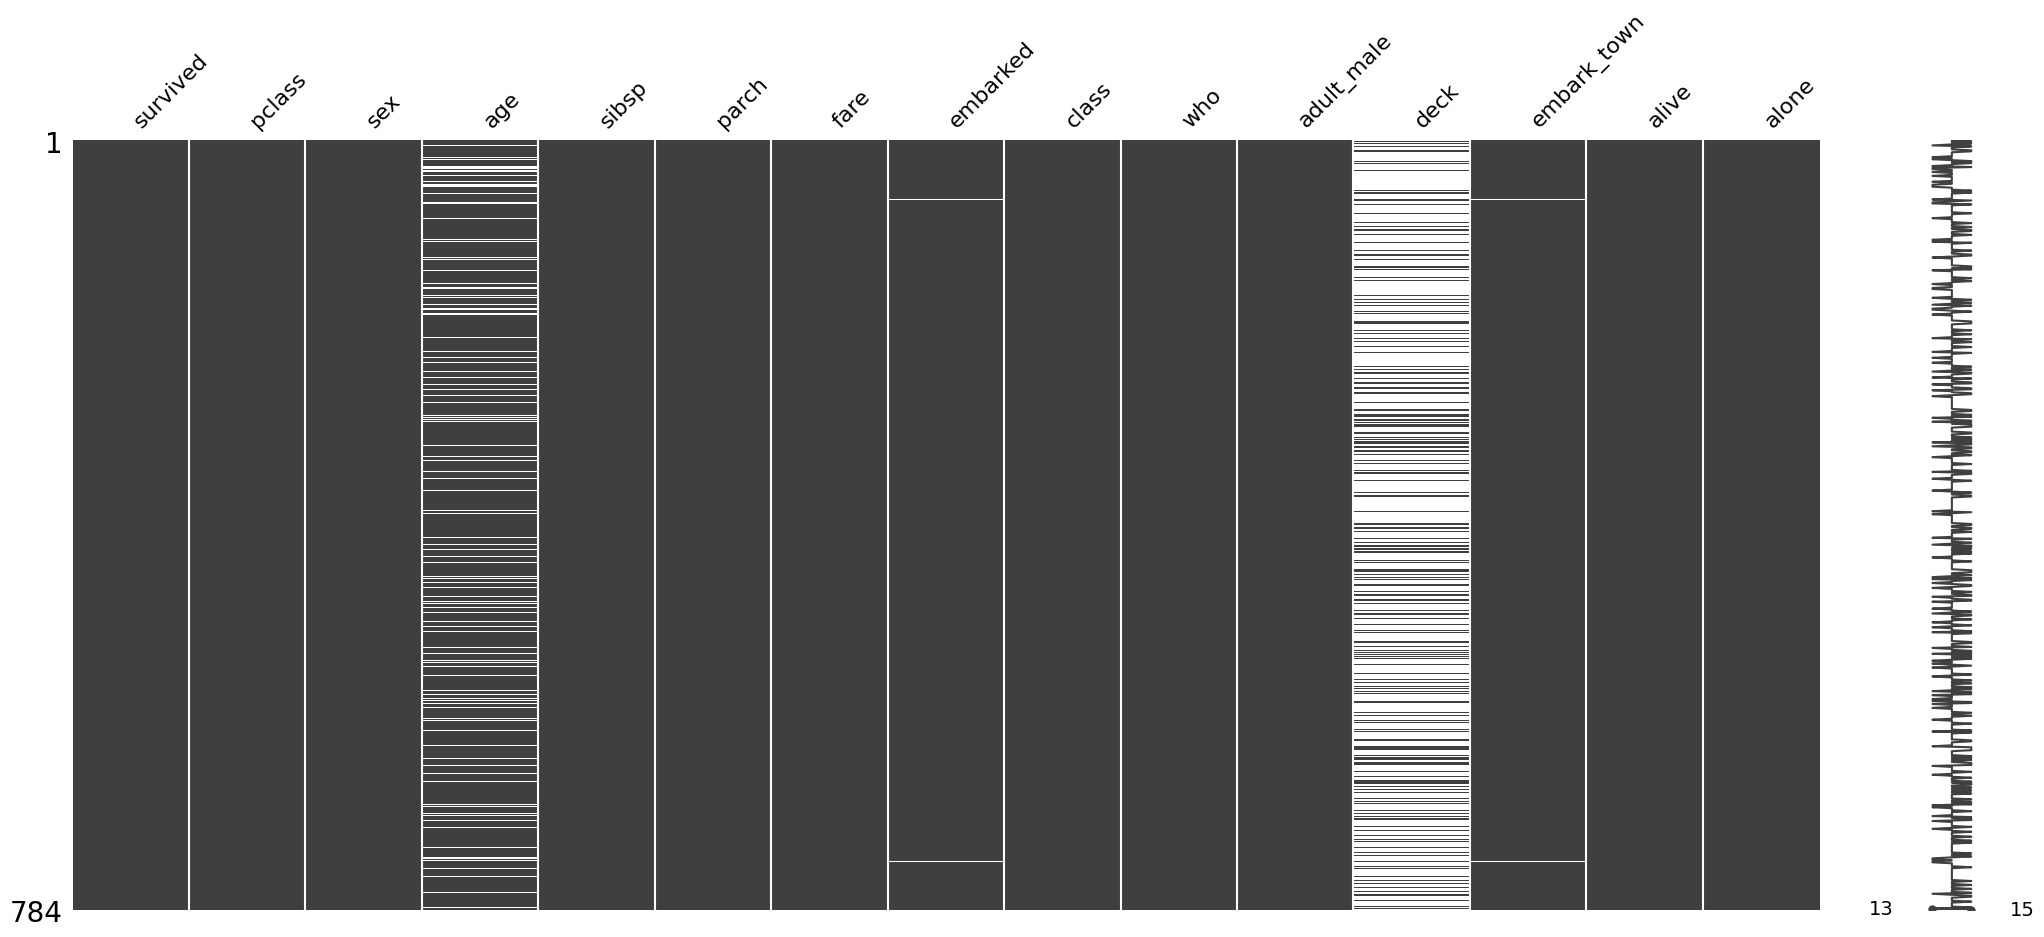

In [42]:
# You may need to install it first: !pip install missingno
import missingno as msno
import matplotlib.pyplot as plt

# This creates a bar chart showing the completeness of every column
msno.bar(df)
plt.show()

# Or a matrix showing where the missing values are located
msno.matrix(df)
plt.show()

In [43]:
df.isna().sum()

,0
survived,0
pclass,0
sex,0
age,106
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [44]:
df["deck"].unique()

[NaN, 'C', 'E', 'G', 'D', 'A', 'B', 'F']
Categories (7, object): ['A', 'B', 'C', 'D', 'E', 'F', 'G']

In [45]:
df.drop("deck",axis=1,inplace=True)

In [46]:
df["age"]=df["age"].fillna(df["age"].mean())
df.embark_town=df.embark_town.fillna(df.embark_town.mode()[0])
df.embarked=df.embarked.fillna(df.embarked.mode()[0])
df.isna().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


In [47]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


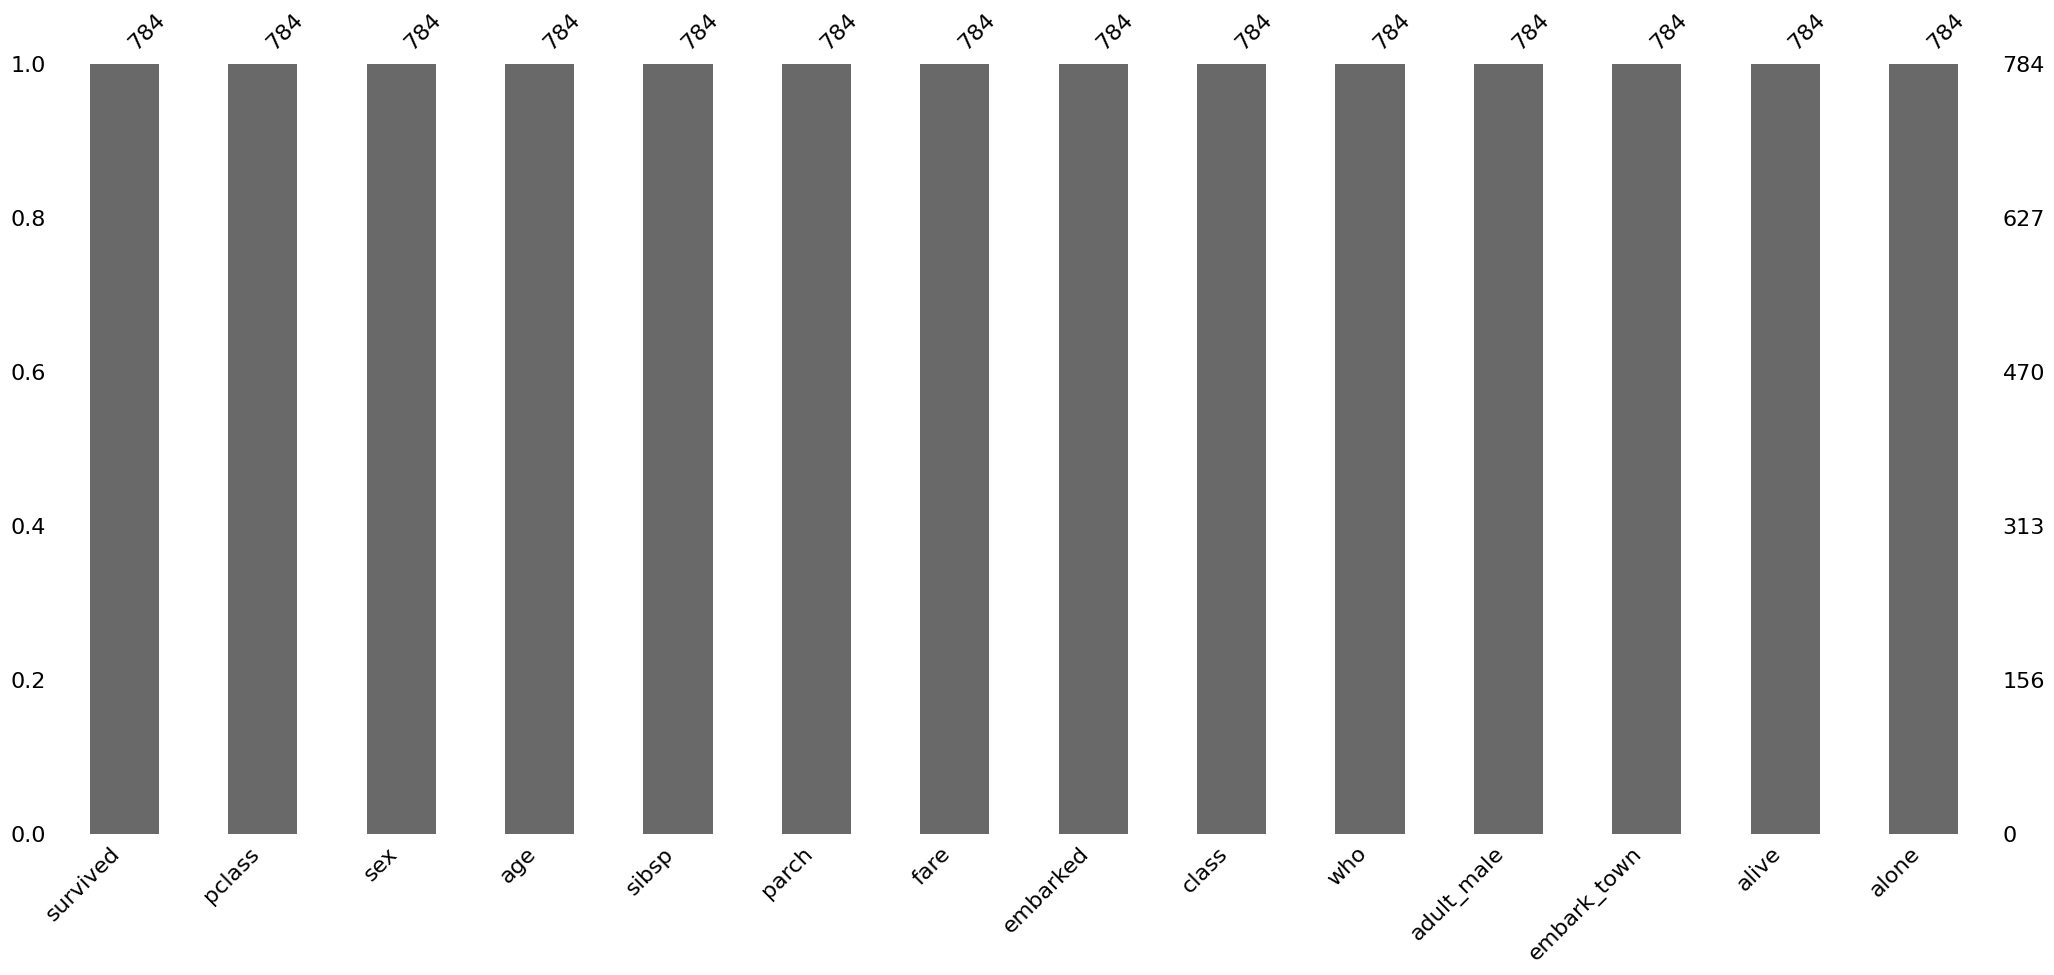

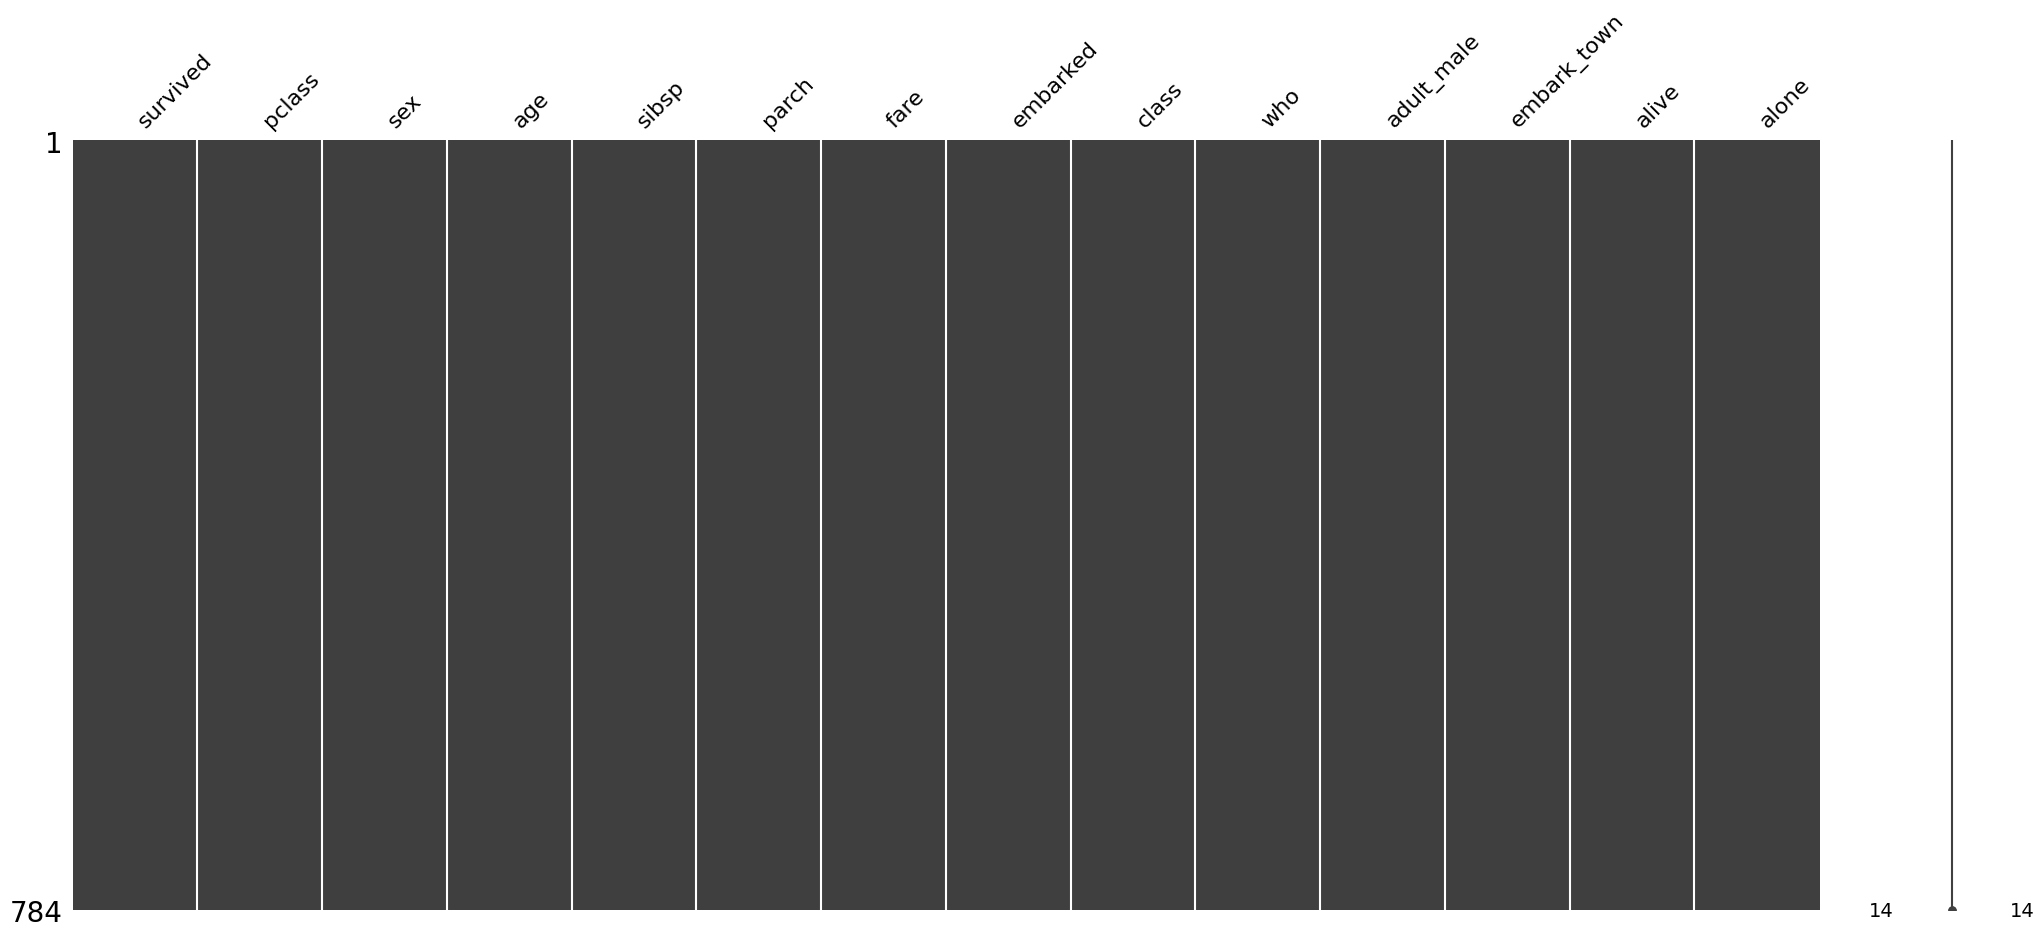

In [48]:
# You may need to install it first: !pip install missingno
import missingno as msno
import matplotlib.pyplot as plt

# This creates a bar chart showing the completeness of every column
msno.bar(df)
plt.show()

# Or a matrix showing where the missing values are located
msno.matrix(df)
plt.show()

Index(['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='object')


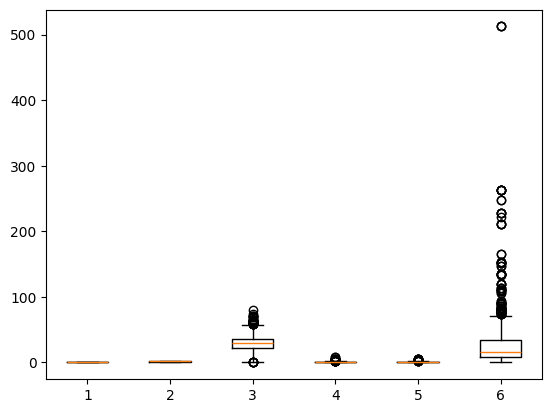

In [49]:
df_box=df.select_dtypes(include=["int64","float64"])
print(df_box.columns)
plt.boxplot(df_box)
plt.show()

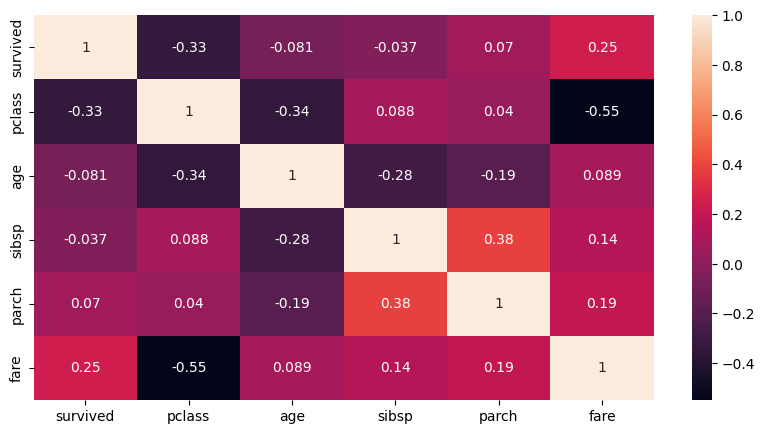

In [50]:
plt.figure(figsize=(10,5))
sns.heatmap(df_box.corr(),annot=True)
plt.show()

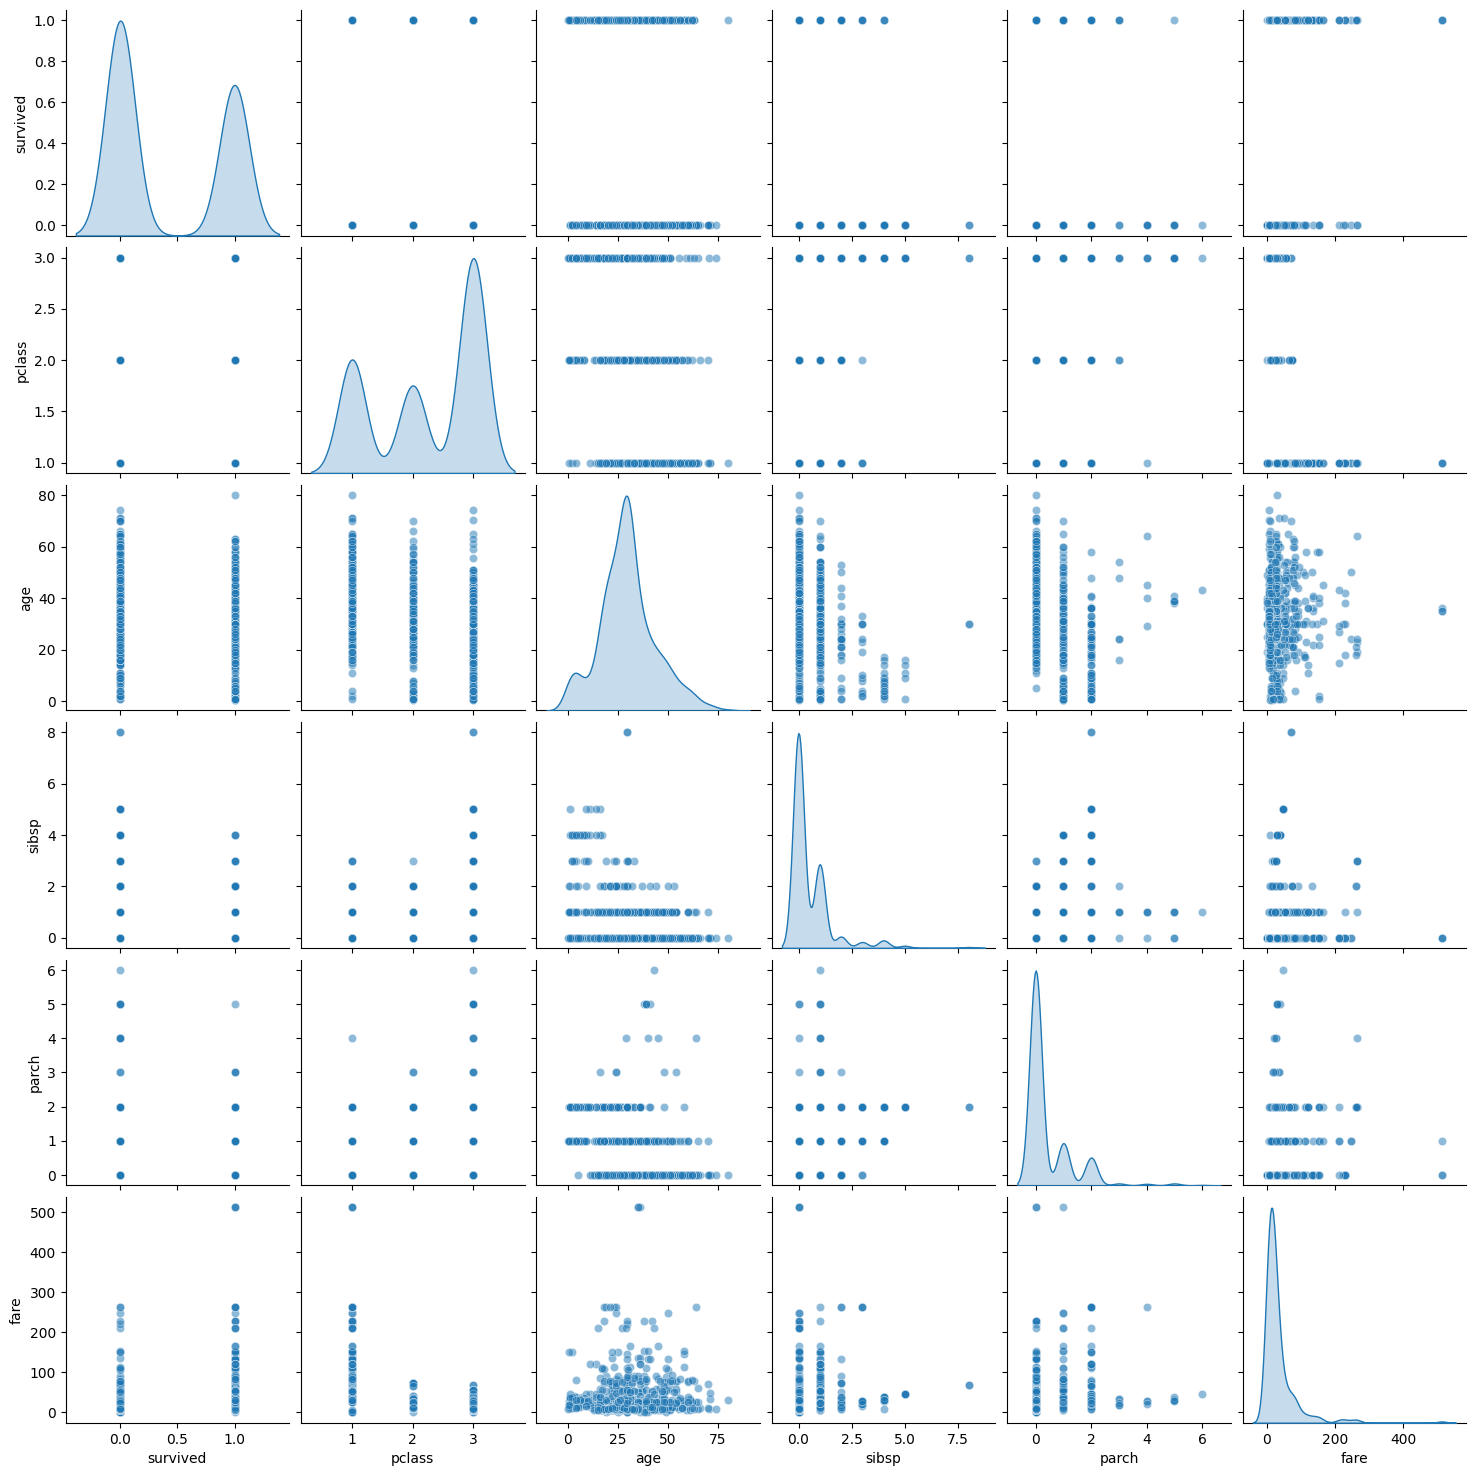

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

# Drop PassengerId if it exists (it's just an index, not a real feature)
if 'PassengerId' in df_box.columns:
    df_box = df_box.drop(columns=['PassengerId'])

# Create the pairplot
sns.pairplot(df_box, diag_kind='kde', plot_kws={'alpha': 0.5})
plt.show()

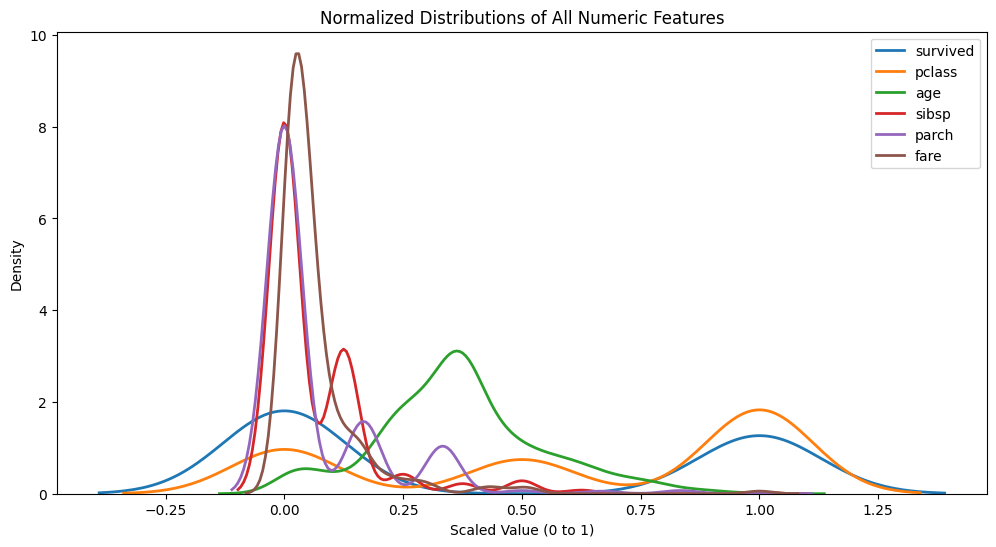

In [52]:
from sklearn.preprocessing import MinMaxScaler
# 1. Scale the data to a 0-1 range so they share the same X-axis
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_box), columns=df_box.columns)

# 2. Plot all the KDE (bell curves) in one single plot
plt.figure(figsize=(12, 6))

for col in df_scaled.columns:
    sns.kdeplot(df_scaled[col], label=col, fill=False, linewidth=2)

plt.title('Normalized Distributions of All Numeric Features')
plt.xlabel('Scaled Value (0 to 1)')
plt.ylabel('Density')
plt.legend()
plt.show()

In [53]:
df.survived.value_counts()

,count
survived,
0,461
1,323


In [54]:
df.pclass.unique()

array([3, 1, 2])

In [55]:
df.groupby("class")["survived"].value_counts()

/tmp/ipykernel_4426/3408769919.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("class")["survived"].value_counts()


class   survived
First   1           135
        0            79
Second  1            84
        0            81
Third   0           301
        1           104
Name: count, dtype: int64

In [56]:
df.groupby("class")["fare"].mean()

/tmp/ipykernel_4426/3866346670.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("class")["fare"].mean()


,fare
class,
First,84.487812
Second,21.835404
Third,13.656223


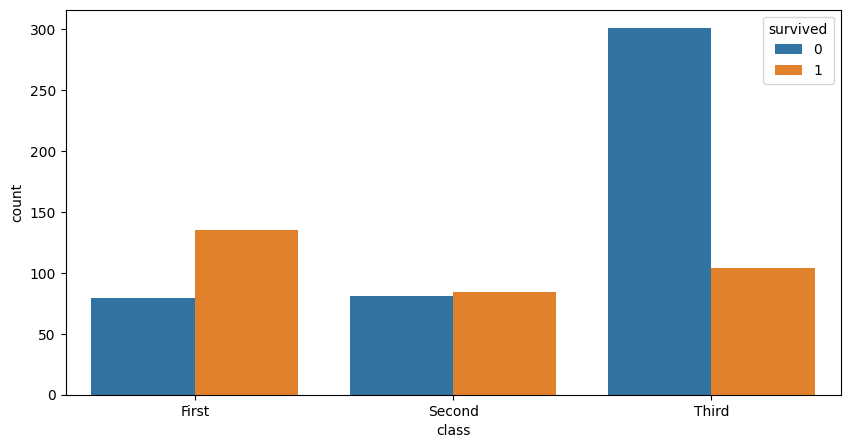

In [57]:
plt.figure(figsize=(10,5))
sns.countplot(x="class",hue="survived",data=df)
plt.show()

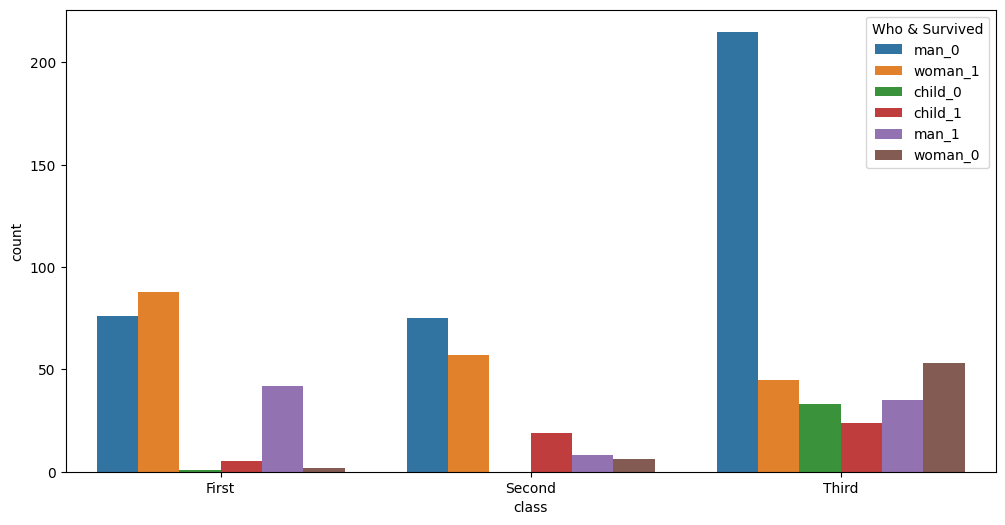

In [58]:
plt.figure(figsize=(12, 6))
# Combine "who" and "survived" into one hue
sns.countplot(x="class", hue=df["who"] + "_" + df["survived"].astype(str), data=df)
plt.legend(title="Who & Survived")
plt.show()

In [59]:
 #The vast majority of men did not survive (especially in 2nd and 3rd class).

In [60]:
final_df= pd.get_dummies(df,drop_first=True).astype(int)
final_df.head()

,survived,pclass,age,sibsp,parch,fare,adult_male,alone,sex_male,embarked_Q,embarked_S,class_Second,class_Third,who_man,who_woman,embark_town_Queenstown,embark_town_Southampton,alive_yes
0,0,3,22,1,0,7,1,0,1,0,1,0,1,1,0,0,1,0
1,1,1,38,1,0,71,0,0,0,0,0,0,0,0,1,0,0,1
2,1,3,26,0,0,7,0,1,0,0,1,0,1,0,1,0,1,1
3,1,1,35,1,0,53,0,0,0,0,1,0,0,0,1,0,1,1
4,0,3,35,0,0,8,1,1,1,0,1,0,1,1,0,0,1,0


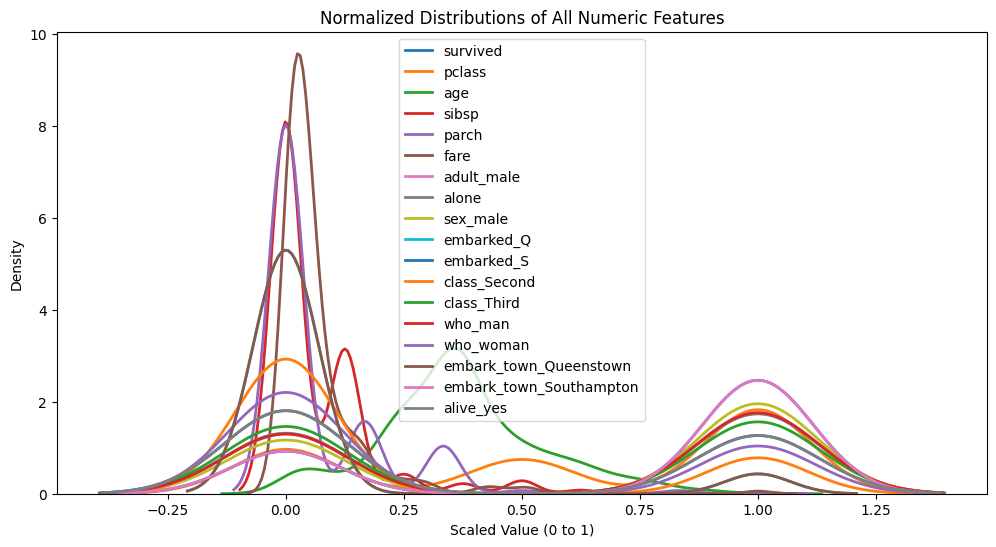

In [61]:
from sklearn.preprocessing import MinMaxScaler
# 1. Scale the data to a 0-1 range so they share the same X-axis
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(final_df), columns=final_df.columns)

# 2. Plot all the KDE (bell curves) in one single plot
plt.figure(figsize=(12, 6))

for col in df_scaled.columns:
    sns.kdeplot(df_scaled[col], label=col, fill=False, linewidth=2)

plt.title('Normalized Distributions of All Numeric Features')
plt.xlabel('Scaled Value (0 to 1)')
plt.ylabel('Density')
plt.legend()
plt.show()

In [62]:
y=final_df["survived"]
X=final_df.drop(columns=["survived", "pclass", "adult_male", "sex_male", "alive_yes"])

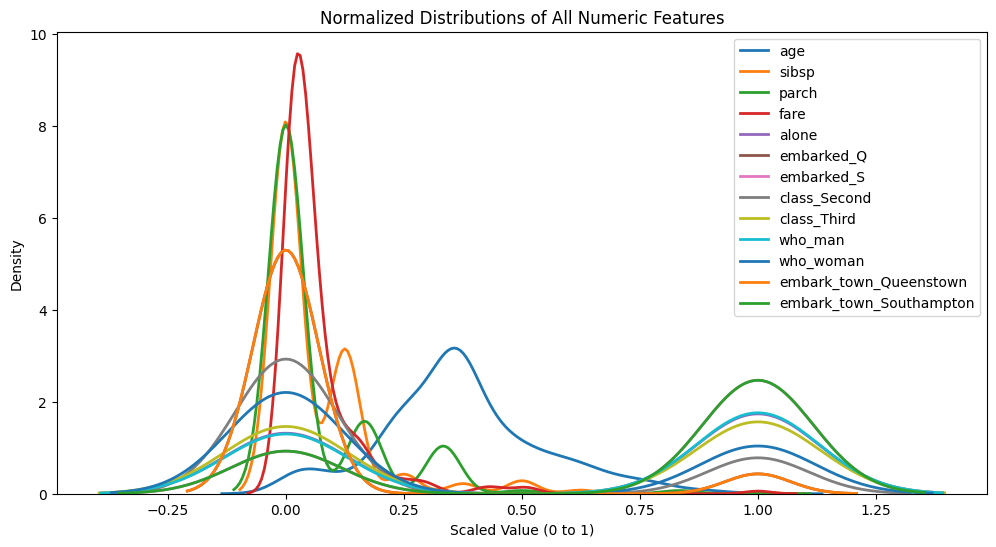

In [63]:
from sklearn.preprocessing import MinMaxScaler
# 1. Scale the data to a 0-1 range so they share the same X-axis
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# 2. Plot all the KDE (bell curves) in one single plot
plt.figure(figsize=(12, 6))

for col in df_scaled.columns:
    sns.kdeplot(df_scaled[col], label=col, fill=False, linewidth=2)

plt.title('Normalized Distributions of All Numeric Features')
plt.xlabel('Scaled Value (0 to 1)')
plt.ylabel('Density')
plt.legend()
plt.show()

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [65]:
lr=LogisticRegression()
lr.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
lr.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [67]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
lr.fit(X_train_scaled,y_train)

LogisticRegression()

In [68]:
y_predect = lr.predict(X_test_scaled)
#accuracy_score, classification_report, confusion_matrix
print(accuracy_score(y_test,y_predect))
print(classification_report(y_test,y_predect))
print(confusion_matrix(y_test,y_predect))

0.8662420382165605
              precision    recall  f1-score   support

           0       0.88      0.89      0.89        92
           1       0.84      0.83      0.84        65

    accuracy                           0.87       157
   macro avg       0.86      0.86      0.86       157
weighted avg       0.87      0.87      0.87       157

[[82 10]
 [11 54]]


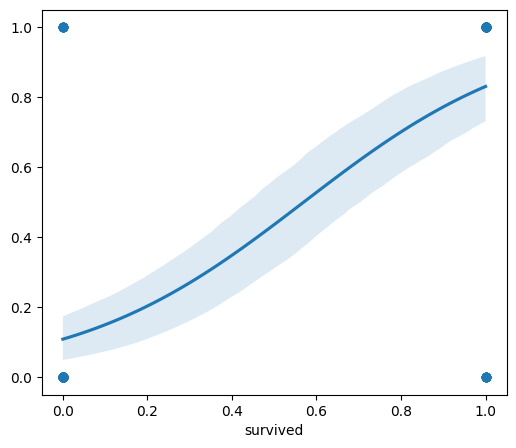

In [69]:
plt.figure(figsize=(6, 5))
sns.regplot(x=y_test, y=y_predect, logistic=True)
plt.show()